In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras import Sequential, datasets
from tensorflow.keras.layers import Dense, Flatten
import warnings

warnings.filterwarnings('ignore')

In [16]:
(X_train, y_train), (X_test, y_test) = datasets.mnist.load_data()

In [17]:
X_train , X_test = X_train/255, X_test/255

# **let's check some of the pictures**

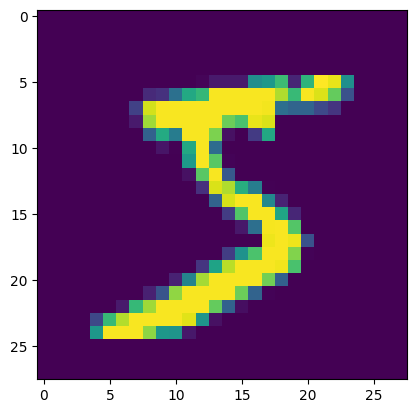

In [18]:
plt.imshow(X_train[0])

In [19]:
y_train[0]

np.uint8(5)

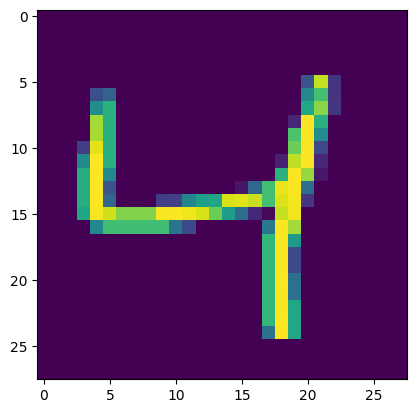

In [20]:
plt.imshow(X_train[2])

In [21]:
y_train[2]

np.uint8(4)

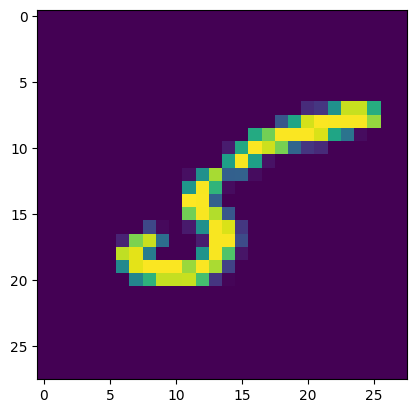

In [22]:
plt.imshow(X_train[11])

In [23]:
y_train[11]

np.uint8(5)

In [41]:
model = Sequential()
model

<Sequential name=sequential_3, built=False>

In [42]:
model.add(Flatten(input_shape=(28,28)))
model.add(Dense(128, activation='relu'))
model.add(Dense(32, activation='relu'))
model.add(Dense(16, activation='relu'))
model.add(Dense(10, activation='softmax'))


model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_4 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 10)             │           170 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 105,306 (411.35 KB)

 Trainable params: 105,306 (411.35 KB)

 Non-trainable params: 0 (0.00 B)

In [43]:
model.compile(loss='sparse_categorical_crossentropy',optimizer='Adam',metrics=['accuracy'])

In [44]:
history = model.fit(X_train, y_train, epochs=20, validation_split= 0.3)

Epoch 1/20
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9062 - loss: 0.3270 - val_accuracy: 0.9505 - val_loss: 0.1706
Epoch 2/20
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9618 - loss: 0.1314 - val_accuracy: 0.9611 - val_loss: 0.1308
Epoch 3/20
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9734 - loss: 0.0887 - val_accuracy: 0.9621 - val_loss: 0.1214
Epoch 4/20
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9791 - loss: 0.0681 - val_accuracy: 0.9606 - val_loss: 0.1336
Epoch 5/20
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9840 - loss: 0.0504 - val_accuracy: 0.9633 - val_loss: 0.1312
Epoch 6/20
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9864 - loss: 0.0424 - val_accuracy: 0.9659 - val_loss: 0.1237
Epoch 7/20
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9880 - loss: 0.0370 - val_accuracy: 0.9627 - val_loss: 0.1418
Epoch 8/20
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9907 - loss: 0.0280 - 

In [45]:
y_probab = model.predict(X_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [46]:
y_probab

array([[3.1440482e-12, 1.7187028e-13, 1.3536312e-09, ..., 1.0000000e+00,
        1.6320816e-12, 1.5646513e-10],
       [5.3528063e-12, 5.4041220e-07, 9.9999940e-01, ..., 3.2062614e-18,
        1.7042791e-10, 4.4068395e-22],
       [1.1683994e-10, 9.9995065e-01, 1.4542078e-06, ..., 4.7678339e-05,
        2.2148329e-07, 3.6194170e-10],
       ...,
       [5.0984625e-18, 2.2640039e-15, 2.2733668e-16, ..., 5.6047680e-11,
        9.7020934e-17, 2.3679070e-09],
       [2.2457630e-12, 6.9479122e-17, 4.1116369e-17, ..., 3.2607826e-18,
        1.9747892e-08, 8.4516507e-14],
       [9.2173813e-10, 2.2213896e-17, 5.5335318e-16, ..., 1.5622293e-22,
        2.1978518e-13, 1.7826356e-18]], dtype=float32)

In [47]:
y_pred = np.argmax(y_probab, axis=1)
y_pred

array([7, 2, 1, ..., 4, 5, 6])

In [48]:
y_test

array([7, 2, 1, ..., 4, 5, 6], dtype=uint8)

In [49]:
y_probab[0][7]

np.float32(1.0)

In [50]:
from sklearn.metrics import accuracy_score

accuracy_score(y_test, y_pred)

0.976

**plottin Loss and accuracy over epoch**

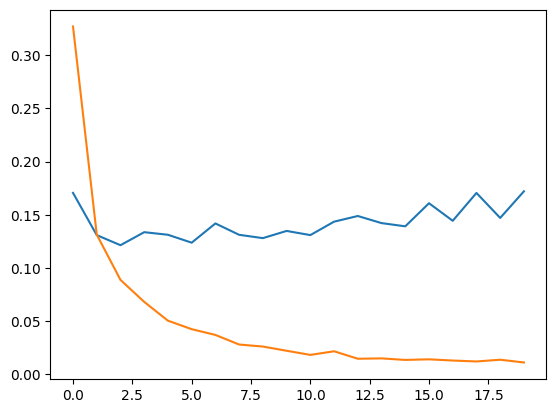

In [52]:
plt.plot(history.history['val_loss'])
plt.plot(history.history['loss'])

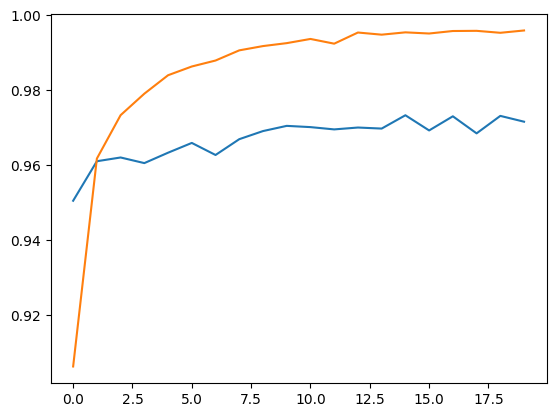

In [53]:
plt.plot(history.history['val_accuracy'])
plt.plot(history.history['accuracy'])

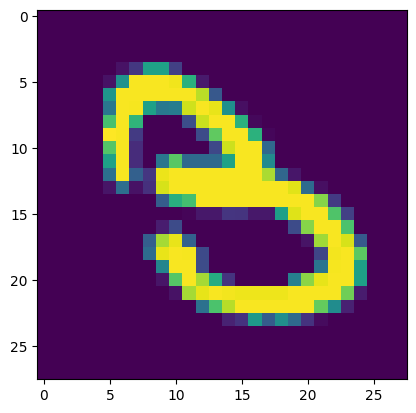

In [57]:
plt.imshow(X_test[18])

In [58]:
model.predict(X_test[18].reshape(1,28,28)).argmax(axis=1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


array([3])